# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _preencha_ · **Tema:** _preencha_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/GabrielSakiyama/IA-2026-02-TP-Chatbot"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [3]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: ChatBot TCC (Chatbot TCC) | Tema: Trabalho de Conclusão de Curso


,intenção,descrição
0,inicio_tcc,como iniciar e registrar o TCC
1,orientador,escolha e papel do orientador
2,prazos,prazos e datas do TCC
3,formatacao,"formato, modelo e normas do texto"
4,banca,banca avaliadora e defesa
5,deposito,entrega e depósito da versão final


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [4]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,massive,total
intencao,,,,
banca,13,37,0,50
chitchat,18,82,0,100
deposito,17,33,0,50
fora_dominio,66,87,37,190
formatacao,13,37,0,50
inicio_tcc,17,33,0,50
orientador,12,38,0,50
prazos,17,33,0,50
total,173,380,37,590


origem,humano,total
intencao,,
banca,20,20
chitchat,32,32
deposito,17,17
fora_dominio,41,41
formatacao,24,24
inicio_tcc,16,16
orientador,17,17
prazos,18,18
total,185,185


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [5]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [6]:
from chatbot.texto import normalizar

# 1. tamanho médio das mensagens (em palavras), por escopo e por origem
palavras = treino["texto"].str.split().str.len()
display(treino.assign(palavras=palavras)
        .pivot_table(index="escopo", columns="origem", values="palavras", aggfunc="mean").round(1))

# 2. termos que mais caracterizam cada rótulo: maior TF-IDF médio dentro do rótulo
vet = tfidf_palavras(ngram_range=(1, 1))
X = vet.fit_transform(treino["texto"])
termos = np.array(vet.get_feature_names_out())
destaque = {}
for rotulo in config.nomes_intencoes + ["chitchat", "fora_dominio"]:
    media = np.asarray(X[(treino["intencao"] == rotulo).to_numpy()].mean(axis=0)).ravel()
    destaque[rotulo] = ", ".join(termos[media.argsort()[::-1][:6]])
display(pd.Series(destaque, name="termos com maior TF-IDF médio").to_frame())

# 3. negativos difíceis: frases fora_dominio com palavras típicas do domínio
ISCAS = {"tcc", "prazo", "orientador", "banca", "defesa", "relatorio", "historico",
         "deposito", "depositar", "formatacao", "modelo", "normas", "abnt", "versao"}
eh_dificil = treino["texto"].map(lambda t: bool(set(normalizar(t).split()) & ISCAS))
fora = treino["intencao"] == "fora_dominio"
print(f"{(fora & eh_dificil).sum()} de {fora.sum()} frases fora_dominio usam palavras típicas do domínio")
display(treino[fora & eh_dificil].groupby("origem").size().rename("negativos difíceis").to_frame())
display(treino[fora & eh_dificil].sample(8, random_state=RANDOM_STATE)[["texto", "origem"]])

origem,humano,llm,massive
escopo,,,
chitchat,3.0,5.8,NaN
dominio,7.8,11.4,NaN
fora_dominio,9.2,10.5,7.4


,termos com maior TF-IDF médio
inicio_tcc,"tcc, meu, comecar, como, do, tema"
orientador,"orientador, professor, como, um, me, posso"
prazos,"do, prazo, tcc, data, datas, para"
formatacao,"abnt, no, normas, tcc, as, tem"
banca,"banca, defesa, da, apresentacao, pode, tempo"
deposito,"versao, deposito, final, arquivo, onde, tcc"
chitchat,"boa, muito, bom, valeu, bot, entendi"
fora_dominio,"de, como, da, qual, para, do"


56 de 190 frases fora_dominio usam palavras típicas do domínio


,negativos difíceis
origem,
humano,28
llm,28


,texto,origem
36,"to fazendo estágio obrigatório, como eu entrego o relatório final do estágio?",humano
46,"Olá, meu amigo do mestrado quer saber quem participa da banca de qualificacao?",humano
484,Tenho dúvidas sobre o formato e as normas ABNT para um seminário da discipli...,llm
56,"O relatorio do estagio e avaliado, sabe me dizer?",humano
70,QUal o prazo para validar as horas complementares desse semestre?,humano
540,Tem um modelo de currículo simples pra baixar?,llm
489,Qual o prazo pra entregar uma encomenda nos Correios?,llm
123,posso ver meu historico escolar?,humano


---
## 3. Representações de texto

In [7]:
# palavras vazias, já sem acento (o tfidf_palavras normaliza o texto antes de separar
# as palavras). As palavras de pergunta (quando, onde, como, qual) ficam de fora da
# lista de propósito: na análise exploratória, "quando" foi um dos termos mais
# típicos de prazos.
PALAVRAS_VAZIAS = [
    "a", "o", "as", "os", "um", "uma", "uns", "umas", "de", "do", "da", "dos", "das",
    "em", "no", "na", "nos", "nas", "num", "numa", "por", "pelo", "pela", "pelos", "pelas",
    "pra", "pro", "para", "com", "sem", "ao", "aos", "e", "ou", "mas", "que", "se",
    "eu", "me", "mim", "meu", "minha", "meus", "minhas", "voce", "vc", "te", "seu", "sua",
    "seus", "suas", "ele", "ela", "eles", "elas", "isso", "isto", "esse", "essa", "este",
    "esta", "ta", "to", "ja", "tb", "tbm", "la", "aqui", "ai", "ne",
]

REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF palavras sem vazias": lambda: tfidf_palavras(stop_words=PALAVRAS_VAZIAS),
    "TF-IDF caracteres": tfidf_caracteres,
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": lambda: MultinomialNB(),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Rede neural (MLP),0.888,0.030,0.892,1.000
1,TF-IDF caracteres,Regressão logística,0.881,0.031,0.888,1.000
2,TF-IDF palavras,Rede neural (MLP),0.870,0.021,0.871,1.000
3,TF-IDF palavras sem vazias,Rede neural (MLP),0.852,0.019,0.856,1.000
4,TF-IDF caracteres,KNN (k=5),0.839,0.031,0.841,0.892
5,TF-IDF palavras,Regressão logística,0.835,0.070,0.856,1.000
6,TF-IDF palavras sem vazias,Regressão logística,0.816,0.070,0.832,1.000
7,TF-IDF palavras,KNN (k=5),0.783,0.047,0.792,0.878
8,TF-IDF palavras sem vazias,KNN (k=5),0.749,0.048,0.766,0.849
9,TF-IDF palavras,Árvore de decisão,0.725,0.039,0.741,1.000


**Escolha do modelo de escopo.** Na comparação acima, a rede neural (MLP) e a
regressão logística, ambas com n-gramas de caracteres, ficaram empatadas: a
diferença entre as médias foi menor que o desvio entre os folds. O grupo escolheu a
**regressão logística**, por ser mais simples, mais rápida e interpretável (dá para
ver o peso de cada n-grama). Abaixo, o ajuste de hiperparâmetros com `GridSearchCV`
e a curva de validação do C.

In [9]:
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],     # C = 1/lambda
                "classificador__class_weight": [None, "balanced"],     # balanced: classes menores pesam mais
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print(busca_escopo.best_params_, round(busca_escopo.best_score_, 3))

{'classificador__C': 10, 'classificador__class_weight': 'balanced', 'vetorizador__ngram_range': (2, 4)} 0.884


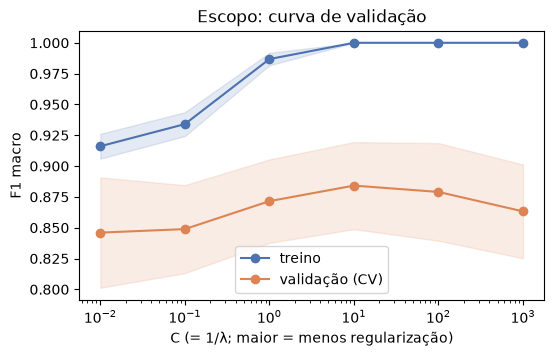

,param_classificador__C,mean_train_score,mean_test_score,std_test_score
2,0.01,0.916,0.846,0.045
6,0.10,0.934,0.849,0.036
10,1.00,0.987,0.872,0.034
14,10.00,1.000,0.884,0.035
18,100.00,1.000,0.879,0.040
22,1000.00,1.000,0.863,0.038


In [10]:
def curva_validacao(busca, titulo):
    """F1 de treino e de validação para cada C, com os outros hiperparâmetros nos melhores valores."""
    res = pd.DataFrame(busca.cv_results_)
    for nome, valor in busca.best_params_.items():
        if nome != "classificador__C":
            res = res[res[f"param_{nome}"].astype(str) == str(valor)]
    res = res.sort_values("param_classificador__C")
    C = res["param_classificador__C"].astype(float)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    for parte, nome, cor in [("train", "treino", CORES[0]), ("test", "validação (CV)", CORES[1])]:
        media, desvio = res[f"mean_{parte}_score"], res[f"std_{parte}_score"]
        ax.plot(C, media, "o-", color=cor, label=nome)
        ax.fill_between(C, media - desvio, media + desvio, color=cor, alpha=0.15)
    ax.set_xscale("log")
    ax.set_xlabel("C (= 1/λ; maior = menos regularização)")
    ax.set_ylabel("F1 macro")
    ax.set_title(titulo)
    ax.legend()
    plt.show()
    return res[["param_classificador__C", "mean_train_score", "mean_test_score", "std_test_score"]].round(3)


curva_validacao(busca_escopo, "Escopo: curva de validação")

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros.

**Qual erro é mais grave no nosso domínio?** O **falso aceite**. Quando o bot
responde com confiança uma pergunta de outro assunto (por exemplo, o prazo do
estágio respondido com as regras do TCC), ele confunde o estudante e pode levá-lo a
perder um prazo de verdade. Na falsa recusa, o estudante é encaminhado ao orientador ou à Coordenação do curso e não recebe informação errada..

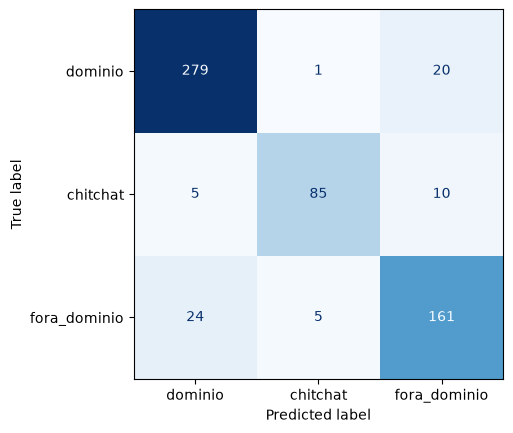

falso aceite: 10.0% das mensagens chitchat/fora_dominio foram tratadas como do domínio
falsa recusa: 7.0% das mensagens do domínio foram recusadas ou tratadas como conversa


,frases,erros,taxa
origem,,,
llm,380,35,0.092
humano,173,26,0.150
massive,37,4,0.108


,texto,escopo,previsto,origem
12,Como assim antecendencia? quantos dias é isso?,dominio,fora_dominio,humano
26,"passei na defesa!! e agora, qual o próximo passo? to meio perdido",dominio,fora_dominio,humano
29,"a carga horária do tcc ainda não apareceu no meu histórico, isso é normal? t...",dominio,fora_dominio,humano
35,"aff, esse tcc não acaba nunca",chitchat,dominio,humano
45,to no mestrado quanto dura a defesa de uma dissertação?,fora_dominio,dominio,humano
...,...,...,...,...
552,que presente posso comprar pra minha amiga que faz aniversario,fora_dominio,dominio,llm
559,o que posso fazer com portátil,fora_dominio,dominio,massive
566,configurar uber,fora_dominio,dominio,massive
569,vai estar de chuva mais tarde,fora_dominio,chitchat,massive


In [11]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()

real = treino["escopo"].to_numpy()
fora_do_tema = real != "dominio"
print(f"falso aceite: {(fora_do_tema & (prev_cv == 'dominio')).sum() / fora_do_tema.sum():.1%} "
      "das mensagens chitchat/fora_dominio foram tratadas como do domínio")
print(f"falsa recusa: {(~fora_do_tema & (prev_cv != 'dominio')).sum() / (~fora_do_tema).sum():.1%} "
      "das mensagens do domínio foram recusadas ou tratadas como conversa")

# os erros se concentram em alguma origem?
erros = treino.assign(previsto=prev_cv).query("escopo != previsto")
display(pd.DataFrame({"frases": treino["origem"].value_counts(), "erros": erros["origem"].value_counts()})
        .fillna(0).astype(int).assign(taxa=lambda d: (d["erros"] / d["frases"]).round(3)))
erros[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [12]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.919,0.029,0.920,1.000
1,TF-IDF caracteres,Rede neural (MLP),0.917,0.018,0.917,1.000
2,TF-IDF palavras sem vazias,Regressão logística,0.912,0.037,0.913,1.000
3,TF-IDF caracteres,Naive Bayes,0.903,0.013,0.903,0.973
4,TF-IDF palavras sem vazias,Naive Bayes,0.893,0.045,0.893,1.000
5,TF-IDF palavras,Regressão logística,0.875,0.059,0.877,1.000
6,TF-IDF palavras sem vazias,Rede neural (MLP),0.872,0.026,0.873,1.000
7,TF-IDF caracteres,KNN (k=5),0.870,0.034,0.870,0.930
8,TF-IDF palavras,Naive Bayes,0.863,0.063,0.863,1.000
9,TF-IDF palavras,Rede neural (MLP),0.857,0.050,0.860,1.000


**Escolha do modelo de tema.** A regressão logística com n-gramas de caracteres
ficou entre as melhores, empatada com a MLP (caracteres) e com a regressão
logística de palavras sem palavras vazias. O grupo a escolheu por ser o mesmo modelo
do escopo (mais simples de manter e explicar) e porque o limiar de confiança
(seção 6) depende das probabilidades, que na regressão logística costumam ser mais
confiáveis que as do Naive Bayes.

Repare que, no tema, tirar as palavras vazias ajudou, ao contrário do escopo: aqui
todas as frases são de estudantes falando do TCC, então "meu", "pra" e "como"
aparecem em todas as intenções e não distinguem nenhuma.

In [13]:
# as 6 intenções têm o mesmo número de frases, então não precisa de class_weight
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"classificador__C": [0.01, 0.1, 1, 10, 100, 1000],
                "vetorizador__ngram_range": [(2, 4), (2, 5)]},
    scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print(busca_tema.best_params_, round(busca_tema.best_score_, 3))

{'classificador__C': 1000, 'vetorizador__ngram_range': (2, 5)} 0.92


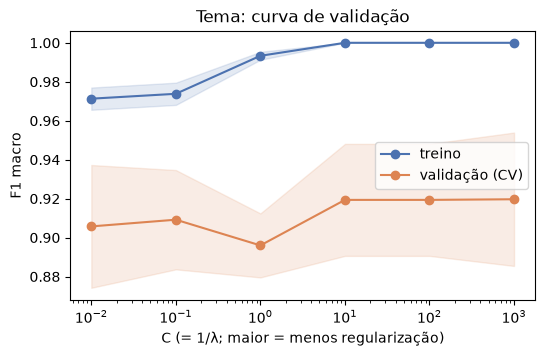

,param_classificador__C,mean_train_score,mean_test_score,std_test_score
1,0.01,0.971,0.906,0.032
3,0.10,0.974,0.909,0.025
5,1.00,0.993,0.896,0.016
7,10.00,1.000,0.919,0.029
9,100.00,1.000,0.919,0.029
11,1000.00,1.000,0.920,0.034


In [14]:
curva_validacao(busca_tema, "Tema: curva de validação")

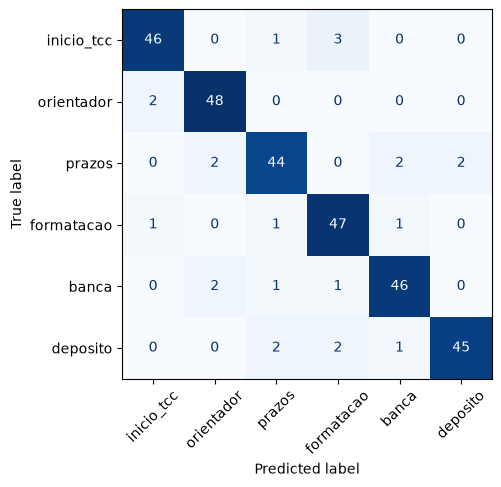

              precision    recall  f1-score   support

       banca       0.92      0.92      0.92        50
    deposito       0.96      0.90      0.93        50
  formatacao       0.89      0.94      0.91        50
  inicio_tcc       0.94      0.92      0.93        50
  orientador       0.92      0.96      0.94        50
      prazos       0.90      0.88      0.89        50

    accuracy                           0.92       300
   macro avg       0.92      0.92      0.92       300
weighted avg       0.92      0.92      0.92       300



erros
intencao   previsto         
inicio_tcc formatacao      3
deposito   prazos          2
banca      orientador      2
orientador inicio_tcc      2
prazos     banca           2
           deposito        2
deposito   formatacao      2
prazos     orientador      2
deposito   banca           1
banca      formatacao      1
           prazos          1
formatacao banca           1
inicio_tcc prazos          1
formatacao inicio_tcc      1
           prazos          1

,frases,erros,taxa
origem,,,
humano,89,15,0.169
llm,211,9,0.043


,texto,intencao,previsto,origem
22,"Me tira uma dúvida: quem escolhe a banca, sou eu ou o meu orientador?",banca,orientador,humano
28,"meu tcc vai ficar público em algum site da faculdade? tipo, qualquer um vai ...",deposito,banca,humano
29,"a carga horária do tcc ainda não apareceu no meu histórico, isso é normal? t...",deposito,formatacao,humano
41,quando vai ser a minha defesa? ainda não me falaram nada,prazos,banca,humano
42,"quem marca a data da defesa, sou eu ou o orientador?",prazos,orientador,humano
100,oq acontece se eu reporvar?,banca,prazos,humano
102,pewcisa anexa no siccad?,deposito,formatacao,humano
104,precisa corrigir o que a banca pediu antes de entregar?,deposito,prazos,humano
132,posso apresentar o tcc antes da colacao ?,prazos,banca,humano
134,tenho que ter tema em mente,inicio_tcc,formatacao,humano


In [15]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

# quais intenções mais se confundem (verdadeira -> prevista)?
erros_tema = treino_dom.assign(previsto=prev_tema).query("intencao != previsto")
display(erros_tema.groupby(["intencao", "previsto"]).size().sort_values(ascending=False)
        .rename("erros").to_frame())

# os erros se concentram em alguma origem?
display(pd.DataFrame({"frases": treino_dom["origem"].value_counts(), "erros": erros_tema["origem"].value_counts()})
        .fillna(0).astype(int).assign(taxa=lambda d: (d["erros"] / d["frases"]).round(3)))
erros_tema[["texto", "intencao", "previsto", "origem"]]

---
## 6. Limiar de confiança

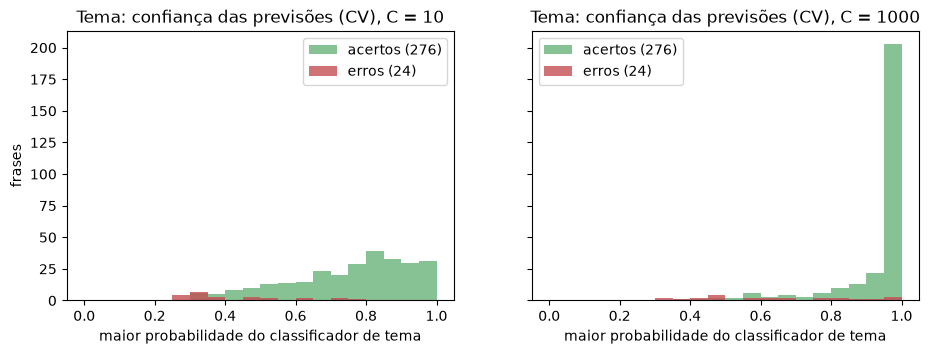

C = 10


,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.920,0,0
1,0.30,0.987,0.932,4,0
2,0.35,0.943,0.954,11,6
3,0.40,0.917,0.964,14,11
4,0.50,0.847,0.972,17,29
5,0.60,0.750,0.978,19,56
6,0.70,0.617,0.984,21,94


C = 1000


,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.920,0,0
1,0.30,1.000,0.920,0,0
2,0.35,0.993,0.926,2,0
3,0.40,0.987,0.929,3,1
4,0.50,0.957,0.948,9,4
5,0.60,0.923,0.953,11,12
6,0.70,0.887,0.966,15,19


In [16]:
def confianca_cv(modelo):
    """Maior probabilidade de cada frase na validação cruzada e se a previsão acertou."""
    proba = cross_val_predict(modelo, treino_dom["texto"], treino_dom["intencao"], cv=cv,
                              method="predict_proba")
    classes = np.array(sorted(treino_dom["intencao"].unique()))
    return proba.max(axis=1), classes[proba.argmax(axis=1)] == treino_dom["intencao"].to_numpy()


def tabela_limiar(confianca, acertou, limiares=(0.0, 0.3, 0.35, 0.4, 0.5, 0.6, 0.7)):
    linhas = []
    for limiar in limiares:
        respondidas = confianca >= limiar
        linhas.append({"limiar": limiar,
                       "% respondidas direto": respondidas.mean(),
                       "acurácia nas respondidas": acertou[respondidas].mean() if respondidas.any() else np.nan,
                       "erros evitados": int((~acertou & ~respondidas).sum()),
                       "acertos que viraram pergunta": int((acertou & ~respondidas).sum())})
    return pd.DataFrame(linhas).round(3)


# C = 10 e C = 1000 empataram no F1 (curva de validação do tema); a diferença aparece nas probabilidades
ngram = busca_tema.best_params_["vetorizador__ngram_range"]
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
bins = np.linspace(0, 1, 21)
tabelas = {}
for ax, C in zip(eixos, (10, 1000)):
    modelo = Pipeline([("vetorizador", tfidf_caracteres(ngram_range=ngram)),
                       ("classificador", LogisticRegression(C=C, max_iter=2000))])
    confianca, acertou = confianca_cv(modelo)
    tabelas[C] = tabela_limiar(confianca, acertou)
    ax.hist(confianca[acertou], bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
    ax.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
    ax.set_title(f"Tema: confiança das previsões (CV), C = {C}")
    ax.set_xlabel("maior probabilidade do classificador de tema")
    ax.legend()
eixos[0].set_ylabel("frases")
plt.show()
for C, tab in tabelas.items():
    print(f"C = {C}")
    display(tab)

**Escolha do C e do limiar.** No F1, C = 10 e C = 1000 empataram, mas as
probabilidades são bem diferentes. Sem regularização (C = 1000), o modelo fica
confiante até nos erros, e o limiar quase não os separa dos acertos. Com C = 10, os
erros se concentram nas confianças baixas. O grupo escolheu **C = 10** e limiar
**0,35** (gravado em `roteamento.limiar_tema`, no `grupo.yaml`): na validação
cruzada, esse limiar evita 11 dos 24 erros e transforma só 6 acertos em perguntas.

Dois cuidados: na avaliação automática, a rota "esclarecer" conta como erro, então
o limiar só custa pontos ali; e essas confianças vêm de um treino majoritariamente
gerado por LLM, então no teste (escrito por pessoas) o bot deve perguntar mais do que
a tabela indica. O grupo considerou que perguntar é melhor que responder errado com
confiança (mesmo critério usado no escopo).

In [17]:
# modelo de tema final (C = 10); é este que a seção 7 salva
clf_tema = Pipeline([("vetorizador", tfidf_caracteres(ngram_range=ngram)),
                     ("classificador", LogisticRegression(C=10, max_iter=2000))])
f1 = cross_validate(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv, scoring="f1_macro")["test_score"]
print(f"tema com C = 10: F1 macro (CV) = {f1.mean():.3f} ± {f1.std():.3f}")
clf_tema.fit(treino_dom["texto"], treino_dom["intencao"])
print("limiar no grupo.yaml:", carregar_config("grupo.yaml").limiar_tema)

tema com C = 10: F1 macro (CV) = 0.919 ± 0.029
limiar no grupo.yaml: 0.35


---
## 6b. Aprofundamento A1: cascata × classificador único

Comparamos a cascata de dois estágios (escopo → tema) com um classificador único de 8 classes (as 6 intenções, chitchat e fora_dominio), nas **mesmas divisões** da validação cruzada, só no treino e sem o limiar. O C do classificador único foi escolhido por GridSearch, como nos dois estágios.

In [18]:
# ---- 6b. Aprofundamento A1: cascata x classificador único ----
from sklearn.base import clone
from sklearn.metrics import f1_score

# 1) Classificador único com as 8 classes (6 intenções + chitchat + fora_dominio).
#    Para a comparação ser justa, o C dele também é escolhido por validação cruzada.
busca_unico = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()),
              ("classificador", LogisticRegression(class_weight="balanced", max_iter=2000))]),
    param_grid={"classificador__C": [1, 10, 100]},
    scoring="f1_macro", cv=cv)
busca_unico.fit(treino["texto"], treino["intencao"])
print("único - melhor C:", busca_unico.best_params_["classificador__C"])
unico = busca_unico.best_estimator_
prev_unico = cross_val_predict(unico, treino["texto"], treino["intencao"], cv=cv)

# 2) A cascata nas MESMAS divisões: o escopo decide; se for "dominio", o tema escolhe a intenção.
prev_cascata = np.empty(len(treino), dtype=object)
for idx_tr, idx_va in cv.split(treino["texto"], treino["intencao"]):
    tr, va = treino.iloc[idx_tr], treino.iloc[idx_va]
    esc = clone(clf_escopo).fit(tr["texto"], tr["escopo"])
    dom = tr[tr["escopo"] == "dominio"]
    tem = clone(clf_tema).fit(dom["texto"], dom["intencao"])
    p_esc = esc.predict(va["texto"])
    p_tem = tem.predict(va["texto"])
    prev_cascata[idx_va] = np.where(p_esc == "dominio", p_tem, p_esc)

# 3) Comparação: F1 por classe, F1 macro, falso aceite e falsa recusa (sem o limiar, nos dois).
rotulos = list(config.nomes_intencoes) + ["chitchat", "fora_dominio"]
real = treino["intencao"].to_numpy()
tab_a1 = pd.DataFrame({nome: f1_score(real, prev, labels=rotulos, average=None)
                       for nome, prev in [("cascata", prev_cascata), ("único", prev_unico)]},
                      index=rotulos)
tab_a1.loc["F1 macro"] = tab_a1.mean()

e_dominio = np.isin(real, config.nomes_intencoes)
for nome, prev in [("cascata", prev_cascata), ("único", prev_unico)]:
    prev_dominio = np.isin(prev, config.nomes_intencoes)
    falso_aceite = (~e_dominio & prev_dominio).sum() / (~e_dominio).sum()
    falsa_recusa = (e_dominio & ~prev_dominio).sum() / e_dominio.sum()
    print(f"{nome}: falso aceite = {falso_aceite:.1%} | falsa recusa = {falsa_recusa:.1%}")
tab_a1.round(3)

único - melhor C: 100
cascata: falso aceite = 9.3% | falsa recusa = 6.0%
único: falso aceite = 7.6% | falsa recusa = 5.3%


,cascata,único
inicio_tcc,0.909,0.931
orientador,0.879,0.852
prazos,0.820,0.837
formatacao,0.828,0.928
banca,0.838,0.835
deposito,0.848,0.889
chitchat,0.897,0.908
fora_dominio,0.854,0.862
F1 macro,0.859,0.880


**Resultado do A1.** O classificador único foi melhor que a cascata em F1 macro (0,880 contra 0,859) e venceu nos 5 folds da validação cruzada, então a diferença não é ruído. Ele também errou menos nos dois tipos de erro: falso aceite de 7,6% contra 9,3% e falsa recusa de 5,3% contra 6,0%. A maior diferença está em `formatacao` (0,928 contra 0,828).

**Por que a cascata perdeu aqui?** Na cascata, os erros dos dois estágios se somam: uma frase do domínio que o escopo recusa por engano nunca chega ao classificador de tema. O classificador único decide tudo de uma vez e compara cada intenção diretamente com `chitchat` e `fora_dominio`, o que parece ajudar quando os negativos difíceis usam o mesmo vocabulário das intenções. Com 590 frases e classes balanceadas, a vantagem de separar o problema em dois mais simples não apareceu.

**Quando a cascata compensa?** Mesmo perdendo no F1, ela tem vantagens que o classificador único não oferece: (1) os erros ficam interpretáveis, porque dá para saber se o bot falhou ao decidir se devia responder (estágio 1) ou ao escolher o assunto (estágio 2); (2) cada estágio pode ter o próprio algoritmo, representação e hiperparâmetros, como fizemos (C e n-gramas diferentes); e (3) o limiar de confiança atua só sobre as intenções, sem misturar a decisão de recusar com a de esclarecer. Por isso, e porque o contrato do código exige dois classificadores (`construir_grafo(config, clf_escopo, clf_tema)`), **o bot entregue continua sendo a cascata**. O A1 mostra que, neste tamanho de dados, o custo dessa escolha é de cerca de 2 pontos de F1 macro na validação cruzada.

---
## 7. Salvar os modelos finais

In [19]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [20]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# teste da busca (não gasta créditos): os trechos vêm só da pasta da intenção e de geral/
pergunta, intencao = "posso fazer tcc em dupla?", "inicio_tcc"
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

trechos  caracteres
intencao   fonte                                                     
banca      banca\banca_e_defesa.md                      8        1624
deposito   deposito\versao_final_e_deposito.md          5         940
formatacao formatacao\formato_e_normas.md               7        2126
           formatacao\manual_apoio_tcc_facom.pdf       11        5689
geral      geral\perguntas_frequentes.md                7        1714
           geral\resolucao_595_cograd_2022.pdf         17        8142
inicio_tcc inicio_tcc\como_iniciar_o_tcc.md             6        1306
orientador orientador\orientacao.md                     6        1538
prazos     prazos\prazos_do_tcc.md                      7        1342

0.35  inicio_tcc\como_iniciar_o_tcc.md | 'Posso fazer o TCC em grupo?\nPode. O TCC pode ser individual ou em grupo. Em grup'
0.21  inicio_tcc\como_iniciar_o_tcc.md | 'Preciso ter orientador antes de registrar?\nSim. O TCC é sempre realizado sob a o'
0.11  inicio_tcc\como_iniciar_o_tcc.md | 'Posso usar um artigo que já publiquei como TCC?\nPode. Um artigo aceito ou public'
0.09  inicio_tcc\como_iniciar_o_tcc.md | 'Quando posso começar o TCC?\nVocê pode iniciar o TCC a qualquer tempo, desde que '


In [21]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
Você é o Brunao, assistente virtual da Universidade dos Desesperados, que sana dúvidas acerca de TCC. Fale de forma simples, direta e de fácil entendimento, tratando o estudante por "você". Responda apenas com base nos trechos dos documentos oficiais; se a informação não estiver neles, diga que não sabe e indique o contato.

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira o seu orientador ou a Coordenação do seu curso.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: como iniciar e registrar o TCC.

Trechos dos documentos oficiais:

[1] (fonte: inicio_tcc\como_iniciar_o_tcc.md)
Posso fazer o TCC em grupo?
Pode. O TCC pode 

In [22]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

# acerto, pergunta sem resposta nos documentos, negativo difícil, regra da data da defesa
# (prazos), e um erro do bot (defesa de mestrado aceita como banca do TCC)
mensagens = [
    "oi!",
    "posso fazer tcc em dupla?",
    "quantos dias tenho pra entregar a versão final depois da defesa?",
    "qual prazo do relatório final do estágio?",
    "qual data da minha defesa?",
    "como funciona a defesa do mestrado?",
    "valeu, tchau",
]
conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in mensagens:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi!
  [rota=chitchat | resposta llm]
  bot: Oi! Como posso ajudar você com o TCC?

você: posso fazer tcc em dupla?
  [rota=inicio_tcc | resposta llm]
  bot: Pode, sim. Em dupla, cada estudante deve ter objetivos e atividades distintos no projeto. [fonte: como_iniciar_o_tcc.md]

você: quantos dias tenho pra entregar a versão final depois da defesa?
  [rota=deposito | resposta llm]
  bot: Não tenho essa informação nos trechos disponíveis. Consulte seu orientador ou a Coordenação do seu curso. [fonte: deposito\versao_final_e_deposito.md]

você: qual prazo do relatório final do estágio?
  [rota=fora_dominio | resposta fixa]
  bot: Desculpe, não sei responder sobre isso. Posso ajudar com: como iniciar e registrar o TCC, escolha e papel do orientador, prazos e datas do TCC, formato, modelo e normas do texto, banca avaliadora e defesa e entrega e depósito da versão final.

você: qual data da minha defesa?
  [rota=prazos | resposta llm]
  bot: Não tenho acesso à data da sua defesa; o ori

---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [23]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),185,0.870,0.858
"tema (2º estágio, oráculo)",112,0.911,0.907
ponta a ponta (grafo),185,0.805,0.826


falso aceite           0.055
falsa recusa           0.107
esclarecimentos        0.049
latência média (ms)    5.212
dtype: float64

,texto,real,rota,confianca_escopo,confianca_intencao
20,Eu não faco ideia de como escolhr o orientaddur me ajuda a escolher,orientador,fora_dominio,0.535324,0.000000
21,ate q dia eu posso iniciar meu tcc e entregar o trabalho,prazos,inicio_tcc,0.985690,0.412355
25,quais os tipos de trabalgo de tcc q posso fazer ?,formatacao,inicio_tcc,0.952002,0.394333
29,E qual idioma você gostaria que sua apresentação/trabalho fosse compartilhado?,formatacao,banca,0.670083,0.403215
30,Onde você mais gostaria de entregar o que foi apresentado do TCC?,deposito,prazos,0.777325,0.411328
58,Como concluir o curso depois do TCC aprovado?,deposito,esclarecer,0.893891,0.329754
60,"Olá, vamos falar sobre meu tcc",chitchat,inicio_tcc,0.493457,0.435514
70,Gostaria de saber qual orientador devo pegar? Qual está com maior tempo disp...,orientador,fora_dominio,0.540518,0.000000
74,Preciso de um requerimento para entregar?,deposito,fora_dominio,0.556748,0.000000
77,Olá QWEN,chitchat,fora_dominio,0.648477,0.000000


---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [24]:
!{sys.executable} scripts/verificar_entrega.py

[ OK  ] grupo.yaml lido: grupo 'ChatBot TCC (Chatbot TCC)', tema 'Trabalho de Conclusão de Curso'
[ OK  ] 6 intenções definidas (exigido: 5 a 10)
[ OK  ] 3 integrante(s) com nome (exigido: 3 a 4)
[ OK  ] treino.csv: 590 mensagens, formato válido
[ OK  ] teste.csv: 185 mensagens, formato válido
[ OK  ] treino: mínimo de 50 exemplos por intenção
[ OK  ] treino: 100 exemplos de chitchat (mínimo 100)
[ OK  ] treino: 190 exemplos de fora_dominio (mínimo 150)
[ OK  ] treino: 29% das frases escritas por pessoas ou coletadas (mínimo 20%)
[ OK  ] teste: mínimo de 15 exemplos por intenção
[ OK  ] teste: 32 exemplos de chitchat (mínimo 30)
[ OK  ] teste: 41 exemplos de fora_dominio (mínimo 40)
[ OK  ] teste: todas as frases escritas por pessoas ou coletadas
[ OK  ] nenhuma frase do teste repetida no treino
[ OK  ] classificadores carregados e com as classes corretas
[ OK  ] grafo responde e devolve 'rota' válida (20 mensagens testadas)
[ OK  ] 9 documento(s) na base de conhecimento (mínimo 5)
[ O